<a href="https://colab.research.google.com/github/jess22jess/Ing_Fin/blob/main/Simulacion_de_Monte_Carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SIMULACION DE MONTE CARLO - FARMACIAS DEL AHORRO
Registros originales: 5500

1. INFORMACION DE LOS DATOS
------------------------------------------------------------
Registros utilizados: 5499
Registros excluidos del modelo: 1
Productos de marca propia: 1648
Productos de marca externa: 3851

2. ESTADISTICA DESCRIPTIVA
------------------------------------------------------------
               Cantidad   Media  Mediana   Varianza  Desviacion_estandar  \
Tipo_marca                                                                 
Marca externa      3851  590.53    414.0  543558.82               737.26   
Marca propia       1648  348.13    207.0  173755.90               416.84   

               Minimo   Maximo  
Tipo_marca                      
Marca externa     5.0  12147.0  
Marca propia      6.0   6291.0  

Precio promedio marca propia: $348.13
Precio promedio marca externa: $590.53
Diferencia observada: 41.05%

3. RESULTADOS DE MONTE CARLO
---------------------------------------------

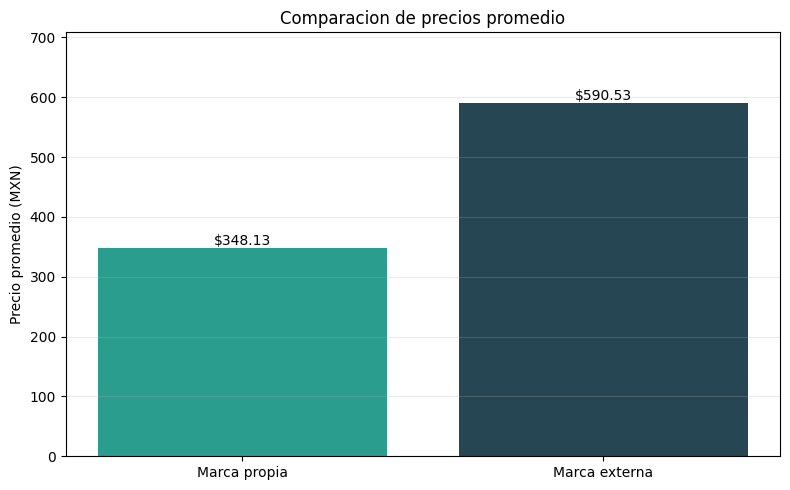

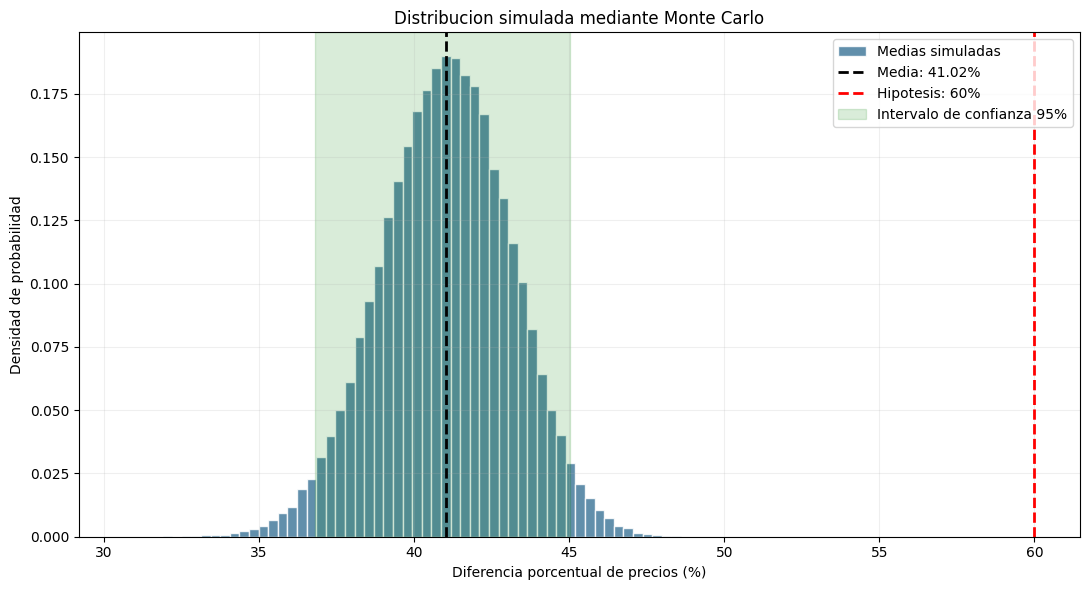

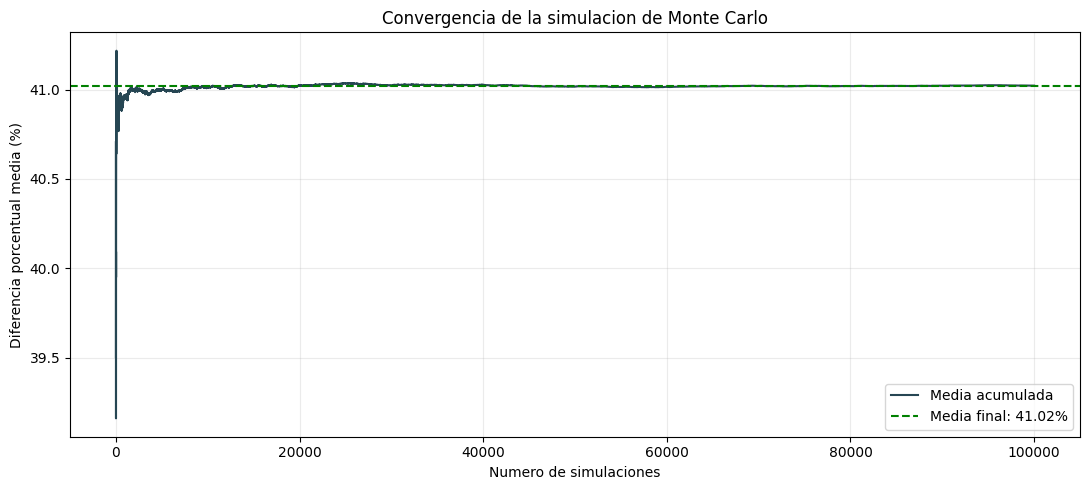

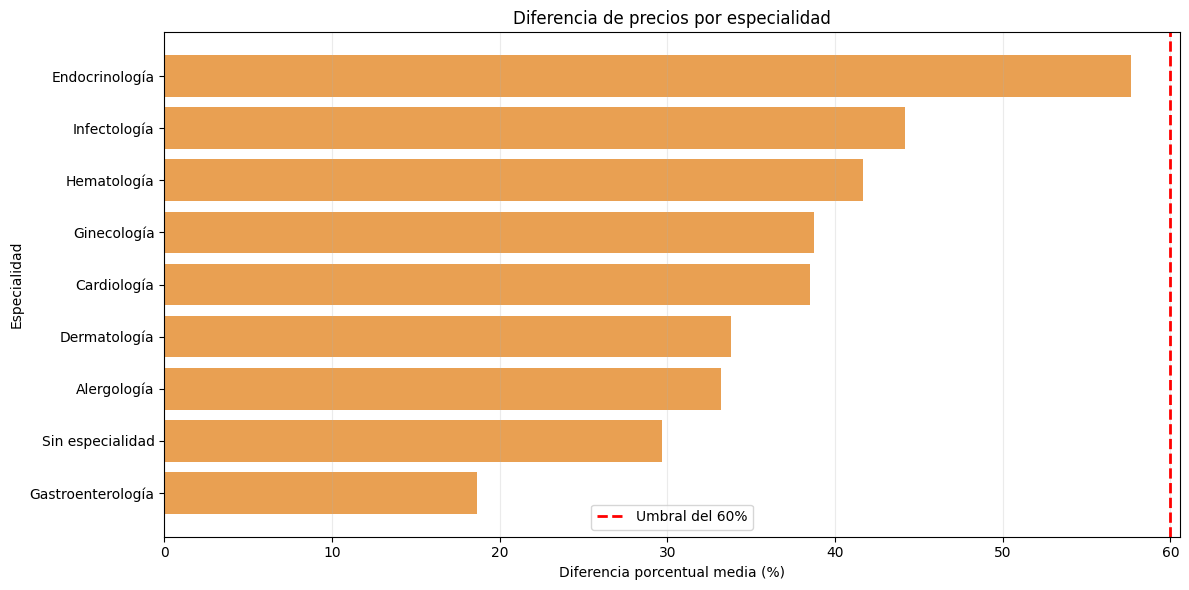

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==========================================================
# SIMULACION DE MONTE CARLO - FARMACIAS DEL AHORRO
# Metodo: Bootstrap no parametrico
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# ==========================================================
# 1. CARGAR LA BASE DE DATOS
# ==========================================================

archivo = "DataLimpia.xlsx"

df = pd.read_excel(archivo, sheet_name="Productos")

print("=" * 60)
print("SIMULACION DE MONTE CARLO - FARMACIAS DEL AHORRO")
print("=" * 60)

print("Registros originales:", len(df))

# ==========================================================
# 2. PARAMETROS DE LA SIMULACION
# ==========================================================

num_simulaciones = 100000
semilla = 42
nivel_confianza = 0.95
umbral = 60

generador = np.random.default_rng(semilla)

# ==========================================================
# 3. PREPARAR LAS VARIABLES
# ==========================================================

df["Precio_actual"] = pd.to_numeric(
    df["Precio_actual"], errors="coerce"
)

df["Es_marca_propia"] = pd.to_numeric(
    df["Es_marca_propia"], errors="coerce"
)

# Clasificar los productos segun la variable del Excel

df["Tipo_marca"] = df["Es_marca_propia"].map({
    1: "Marca propia",
    0: "Marca externa"
})

# Extraer las especialidades medicas

def extraer_especialidades(texto):

    especialidades = re.findall(
        r"\|\s*([^|]+?)\s*-\s*Especialidades\s*-\s*Farmacia",
        str(texto),
        flags=re.IGNORECASE
    )

    especialidades = sorted(set(
        e.strip() for e in especialidades
    ))

    return especialidades or ["Sin especialidad"]


df["Especialidad"] = df["Categorias_encontradas"].apply(
    extraer_especialidades
)

# Seleccionar registros validos exclusivamente para el modelo.
# No se modifica ni se elimina informacion del Excel original.

datos = df[
    (df["Precio_actual"] > 0) &
    (df["Es_marca_propia"].isin([0, 1]))
].copy()

# ==========================================================
# 4. SEPARAR LOS PRECIOS POR TIPO DE MARCA
# ==========================================================

precios_propia = datos.loc[
    datos["Es_marca_propia"] == 1,
    "Precio_actual"
].to_numpy()

precios_externa = datos.loc[
    datos["Es_marca_propia"] == 0,
    "Precio_actual"
].to_numpy()

print("\n1. INFORMACION DE LOS DATOS")
print("-" * 60)

print("Registros utilizados:", len(datos))
print("Registros excluidos del modelo:", len(df) - len(datos))
print("Productos de marca propia:", len(precios_propia))
print("Productos de marca externa:", len(precios_externa))

# ==========================================================
# 5. ESTADISTICA DESCRIPTIVA
# ==========================================================

estadisticas = datos.groupby("Tipo_marca")["Precio_actual"].agg(
    Cantidad="count",
    Media="mean",
    Mediana="median",
    Varianza="var",
    Desviacion_estandar="std",
    Minimo="min",
    Maximo="max"
).round(2)

media_propia = np.mean(precios_propia)
media_externa = np.mean(precios_externa)

diferencia_observada = (
    (media_externa - media_propia) /
    media_externa * 100
)

print("\n2. ESTADISTICA DESCRIPTIVA")
print("-" * 60)
print(estadisticas)

print(f"\nPrecio promedio marca propia: ${media_propia:.2f}")
print(f"Precio promedio marca externa: ${media_externa:.2f}")
print(f"Diferencia observada: {diferencia_observada:.2f}%")

# ==========================================================
# 6. FUNCION DE SIMULACION DE MONTE CARLO
# ==========================================================

def monte_carlo(propia, externa, simulaciones):

    resultados = np.zeros(simulaciones)

    cantidad_propia = len(propia)
    cantidad_externa = len(externa)

    for i in range(simulaciones):

        # Seleccionar muestras aleatorias con reemplazo

        muestra_propia = generador.choice(
            propia,
            size=cantidad_propia,
            replace=True
        )

        muestra_externa = generador.choice(
            externa,
            size=cantidad_externa,
            replace=True
        )

        # Calcular las medias simuladas

        promedio_propia = np.mean(muestra_propia)
        promedio_externa = np.mean(muestra_externa)

        # Calcular diferencia porcentual

        resultados[i] = (
            (promedio_externa - promedio_propia) /
            promedio_externa * 100
        )

    return resultados

# Ejecutar las 100,000 simulaciones

resultados = monte_carlo(
    precios_propia,
    precios_externa,
    num_simulaciones
)

# ==========================================================
# 7. RESULTADOS ESTADISTICOS DE MONTE CARLO
# ==========================================================

media_simulada = np.mean(resultados)
mediana_simulada = np.median(resultados)
varianza = np.var(resultados, ddof=1)
desviacion = np.std(resultados, ddof=1)

alfa = 1 - nivel_confianza

limite_inferior, limite_superior = np.percentile(
    resultados,
    [100 * alfa / 2, 100 * (1 - alfa / 2)]
)

# Limite unilateral para evaluar la hipotesis

limite_unilateral = np.percentile(
    resultados, 100 * alfa
)

# Proporcion de simulaciones que superan el 60%

proporcion_superior = np.mean(resultados > umbral) * 100

# Error numerico de la media de Monte Carlo

error_monte_carlo = desviacion / np.sqrt(num_simulaciones)

print("\n3. RESULTADOS DE MONTE CARLO")
print("-" * 60)

print(f"Numero de simulaciones: {num_simulaciones:,}")
print(f"Media simulada: {media_simulada:.4f}%")
print(f"Mediana: {mediana_simulada:.4f}%")
print(f"Varianza: {varianza:.4f}")
print(f"Desviacion estandar: {desviacion:.4f}")
print(f"Error de Monte Carlo: {error_monte_carlo:.6f}")
print(f"Valor minimo: {np.min(resultados):.4f}%")
print(f"Valor maximo: {np.max(resultados):.4f}%")

print(
    f"Intervalo de confianza del 95%: "
    f"[{limite_inferior:.4f}%, {limite_superior:.4f}%]"
)

print(
    f"Limite inferior unilateral: "
    f"{limite_unilateral:.4f}%"
)

print(
    f"Simulaciones superiores al 60%: "
    f"{proporcion_superior:.4f}%"
)

# ==========================================================
# 8. EVALUACION DE LA HIPOTESIS COMERCIAL
# ==========================================================

print("\n4. EVALUACION DE LA HIPOTESIS")
print("-" * 60)

print("H0: Diferencia media <= 60%")
print("H1: Diferencia media > 60%")
print("Nivel de significancia:", alfa)

if limite_unilateral > umbral:

    conclusion = (
        "Se rechaza H0. Existe evidencia de que "
        "la diferencia comercial supera el 60%."
    )

else:

    conclusion = (
        "No se rechaza H0. No existe evidencia suficiente "
        "de que la diferencia comercial supere el 60%."
    )

print(conclusion)

# ==========================================================
# 9. SIMULACION POR ESPECIALIDAD
# ==========================================================

# Un producto puede pertenecer a varias especialidades.
# Se analiza cada especialidad de manera independiente.

datos_especialidad = datos.explode("Especialidad")

resultados_especialidad = []

# Minimo exploratorio de productos por tipo de marca

minimo_productos = 10

for especialidad, grupo in datos_especialidad.groupby(
    "Especialidad"
):

    propia = grupo.loc[
        grupo["Es_marca_propia"] == 1,
        "Precio_actual"
    ].to_numpy()

    externa = grupo.loc[
        grupo["Es_marca_propia"] == 0,
        "Precio_actual"
    ].to_numpy()

    if (
        len(propia) >= minimo_productos and
        len(externa) >= minimo_productos
    ):

        simulacion = monte_carlo(
            propia,
            externa,
            num_simulaciones
        )

        inferior, superior = np.percentile(
            simulacion, [2.5, 97.5]
        )

        unilateral = np.percentile(simulacion, 5)

        resultados_especialidad.append({

            "Especialidad": especialidad,

            "Productos_marca_propia": len(propia),

            "Productos_marca_externa": len(externa),

            "Precio_promedio_propia": np.mean(propia),

            "Precio_promedio_externa": np.mean(externa),

            "Diferencia_media": np.mean(simulacion),

            "Desviacion_estandar": np.std(
                simulacion, ddof=1
            ),

            "Limite_inferior": inferior,

            "Limite_superior": superior,

            "Limite_unilateral": unilateral,

            "Porcentaje_superior_60": np.mean(
                simulacion > umbral
            ) * 100,

            "Conclusion": (
                "Rechazar H0" if unilateral > umbral
                else "No rechazar H0"
            )

        })

tabla_especialidades = pd.DataFrame(
    resultados_especialidad
)

if not tabla_especialidades.empty:

    tabla_especialidades = (
        tabla_especialidades
        .sort_values("Diferencia_media", ascending=False)
        .round(4)
    )

print("\n5. RESULTADOS POR ESPECIALIDAD")
print("-" * 60)
print(tabla_especialidades.to_string(index=False))

# ==========================================================
# 10. GRAFICA DE PRECIOS PROMEDIO
# ==========================================================

plt.figure(figsize=(8, 5))

tipos = ["Marca propia", "Marca externa"]
promedios = [media_propia, media_externa]

barras = plt.bar(
    tipos, promedios,
    color=["#2A9D8F", "#264653"]
)

for barra, valor in zip(barras, promedios):

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor,
        f"${valor:,.2f}",
        ha="center",
        va="bottom"
    )

plt.title("Comparacion de precios promedio")
plt.ylabel("Precio promedio (MXN)")
plt.ylim(0, max(promedios) * 1.20)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ==========================================================
# 11. HISTOGRAMA DE MONTE CARLO
# ==========================================================

plt.figure(figsize=(11, 6))

plt.hist(
    resultados,
    bins=60,
    density=True,
    color="#457B9D",
    edgecolor="white",
    alpha=0.85,
    label="Medias simuladas"
)

plt.axvline(
    media_simulada,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Media: {media_simulada:.2f}%"
)

plt.axvline(
    umbral,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Hipotesis: 60%"
)

plt.axvspan(
    limite_inferior,
    limite_superior,
    color="green",
    alpha=0.15,
    label="Intervalo de confianza 95%"
)

plt.title("Distribucion simulada mediante Monte Carlo")
plt.xlabel("Diferencia porcentual de precios (%)")
plt.ylabel("Densidad de probabilidad")
plt.legend()
plt.grid(alpha=0.20)
plt.tight_layout()
plt.show()

# ==========================================================
# 12. GRAFICA DE CONVERGENCIA
# ==========================================================

iteraciones = np.arange(1, num_simulaciones + 1)

media_acumulada = (
    np.cumsum(resultados) / iteraciones
)

plt.figure(figsize=(11, 5))

plt.plot(
    iteraciones,
    media_acumulada,
    color="#264653",
    label="Media acumulada"
)

plt.axhline(
    media_simulada,
    color="green",
    linestyle="--",
    label=f"Media final: {media_simulada:.2f}%"
)

plt.title("Convergencia de la simulacion de Monte Carlo")
plt.xlabel("Numero de simulaciones")
plt.ylabel("Diferencia porcentual media (%)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ==========================================================
# 13. GRAFICA POR ESPECIALIDAD
# ==========================================================

if not tabla_especialidades.empty:

    tabla_grafica = tabla_especialidades.sort_values(
        "Diferencia_media"
    )

    colores = [
        "#2A9D8F" if valor > umbral else "#E9A052"
        for valor in tabla_grafica["Diferencia_media"]
    ]

    plt.figure(figsize=(
        12,
        max(6, len(tabla_grafica) * 0.45)
    ))

    plt.barh(
        tabla_grafica["Especialidad"],
        tabla_grafica["Diferencia_media"],
        color=colores
    )

    plt.axvline(
        umbral,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Umbral del 60%"
    )

    plt.title("Diferencia de precios por especialidad")
    plt.xlabel("Diferencia porcentual media (%)")
    plt.ylabel("Especialidad")
    plt.legend()
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


# Descargar el archivo si se trabaja en Google Colab

try:
    from google.colab import files
    files.download(archivo_salida)
except ImportError:
    pass


# Simulación de Monte Carlo
### Farmacias del Ahorro — Análisis de precios

**Objetivo general**

Analizar las diferencias económicas entre los productos
de marca propia y marcas externas de Farmacias del Ahorro,
utilizando información obtenida mediante Web Scraping.

**Objetivo de la simulación**

Estimar la distribución de la diferencia porcentual de
precios promedio mediante remuestreo aleatorio con reemplazo.

**Hipótesis original del proyecto**

La diferencia media de precios entre medicamentos de
patente y genéricos supera el 60%, con variaciones
según la clase terapéutica.

**Alcance del análisis**

La base de datos no permite identificar de manera confiable
los medicamentos genéricos y de patente. Por ello, se realiza
una comparación comercial entre marcas propias y externas.

Los resultados no constituyen una comparación directa de
medicamentos farmacológicamente equivalentes.


---
## 1. Lectura de la base de datos


Se importa la base limpia obtenida del proceso de Web Scraping.
Se conserva la información original y únicamente se seleccionan
los registros válidos para realizar la simulación.


Registros originales: 5,500
Columnas originales:  39

Primeros cinco registros de las variables de estudio:


,Nombre_producto,Marca,Precio_actual,Es_marca_propia
0,Esoxx One 20 Unidades 10 ml,ESOXX-ONE,465.500000,0.0
1,Riopan Gel Oral 20 sobres,RIOPAN,286.000000,0.0
2,Omeprazol 20 mg Oral 30 cápsulas 2 Cajas Marca...,Marca del Ahorro,151.000000,1.0
3,Neuralin Solución Inyectable 2 pz,NEURALIN,147.050003,0.0
4,Alka Seltzer Alivio del Malestar Estomacal y D...,ALKA-SELTZER,48.000000,0.0


---
## 2. Parámetros de la simulación

... (7 outputs left out)

Tipo_marca,Marca externa,Marca propia
Cantidad,"3,851.00","1,648.00"
Media,590.53,348.13
Mediana,414.00,207.00
Varianza,"543,558.82","173,755.90"
Desviacion_estandar,737.26,416.84
Minimo,5.00,6.00
Maximo,"12,147.00","6,291.00"



RESULTADOS OBSERVADOS
-------------------------------------------------------
Precio promedio marca propia:   $348.13
Precio promedio marca externa:  $590.53
Diferencia porcentual:           41.0471%


---
## 5. Comparación de precios promedio


La siguiente gráfica compara los precios promedio observados
en la base de datos antes de realizar las simulaciones.

Permite identificar cuál de los dos grupos presenta
un precio promedio mayor.


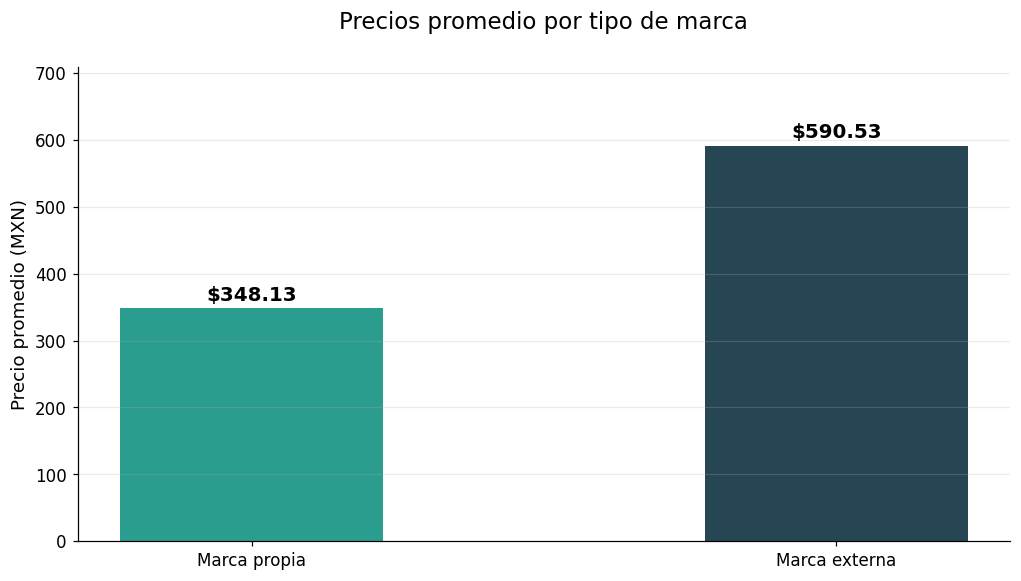

---

---
## 6. Simulación de Monte Carlo


Se utiliza el método Bootstrap no paramétrico porque
permite generar muestras aleatorias a partir de los
precios reales, sin asumir una distribución específica.

En cada iteración:

1. Se seleccionan precios de marca propia con reemplazo.
2. Se seleccionan precios de marca externa con reemplazo.
3. Se calcula el precio promedio de cada muestra.
4. Se obtiene la diferencia porcentual.
5. Se almacena el resultado de la simulación.

La diferencia porcentual se calcula mediante:

$$
D_i=
\left(
1-\frac{\overline{P}_{propia,i}}
{\overline{P}_{externa,i}}
\right)100
$$

El procedimiento se repite 100,000 veces.


Iniciando simulación general...

Simulación general completada correctamente.
Total de iteraciones realizadas: 100,000

Primeras diez iteraciones:


,Iteracion,Diferencia_porcentual
0,1,39.5043%
1,2,40.7472%
2,3,41.8810%
3,4,39.7903%
4,5,38.4090%
5,6,37.0332%
6,7,36.7673%
7,8,44.0046%
8,9,40.2298%
9,10,41.9308%


---
## 7. Resultados estadísticos de Monte Carlo


La media simulada representa la diferencia porcentual
promedio obtenida en las 100,000 iteraciones.

$$
\widehat{\mu}_{MC}=
\frac{1}{N}\sum_{i=1}^{N}D_i
$$

La varianza y la desviación estándar permiten analizar
la dispersión de las diferencias simuladas.

El error estándar de Monte Carlo mide la precisión
numérica de la media obtenida:

$$
EE_{MC}=\frac{S}{\sqrt{N}}
$$

El intervalo Bootstrap se obtiene mediante los
percentiles de la distribución simulada.


,Indicador,Resultado
0,Diferencia observada,41.0471%
1,Media simulada,41.0216%
2,Mediana simulada,41.0629%
3,Varianza,4.4090
4,Desviación estándar,2.0998
5,Error de Monte Carlo,0.006640
6,Valor mínimo,30.6544%
7,Valor máximo,49.2193%
8,Límite inferior IC 95%,36.8070%
9,Límite superior IC 95%,45.0290%


---
## 8. Distribución de las diferencias simuladas


El histograma representa la distribución empírica de las
100,000 diferencias porcentuales obtenidas.

La línea negra representa la media simulada, la región verde
corresponde al intervalo Bootstrap del 95% y la línea roja
indica el umbral del 60% establecido para la comparación.


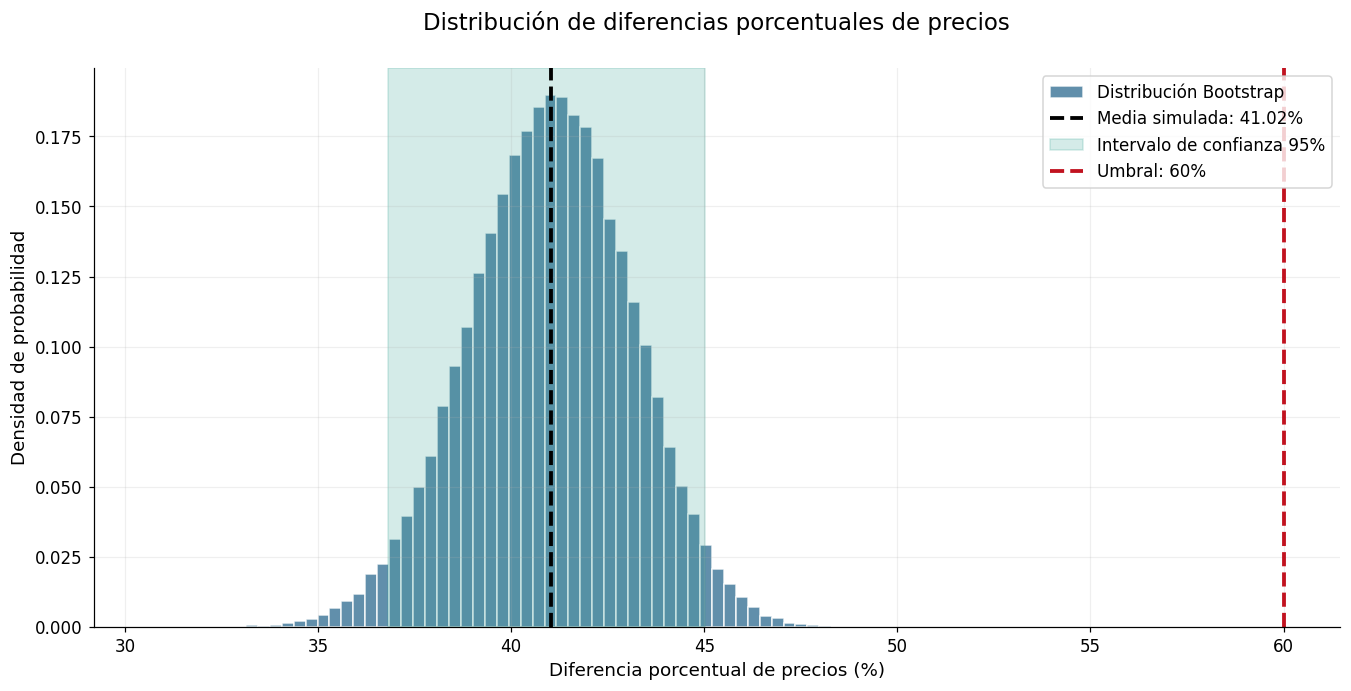

---

---
## 9. Convergencia del método de Monte Carlo


La gráfica de convergencia muestra cómo cambia la media
acumulada conforme aumenta el número de simulaciones.

Una estabilización de la media indica que el estimador
numérico presenta menor variabilidad conforme se realizan
más iteraciones.


,Iteraciones,Media_acumulada,Error_Monte_Carlo
0,10,40.0298%,0.714760
1,100,40.9237%,0.238999
2,"1,000",40.9509%,0.064802
3,"10,000",41.0121%,0.020879
4,"50,000",41.0161%,0.009420
5,"100,000",41.0216%,0.006640


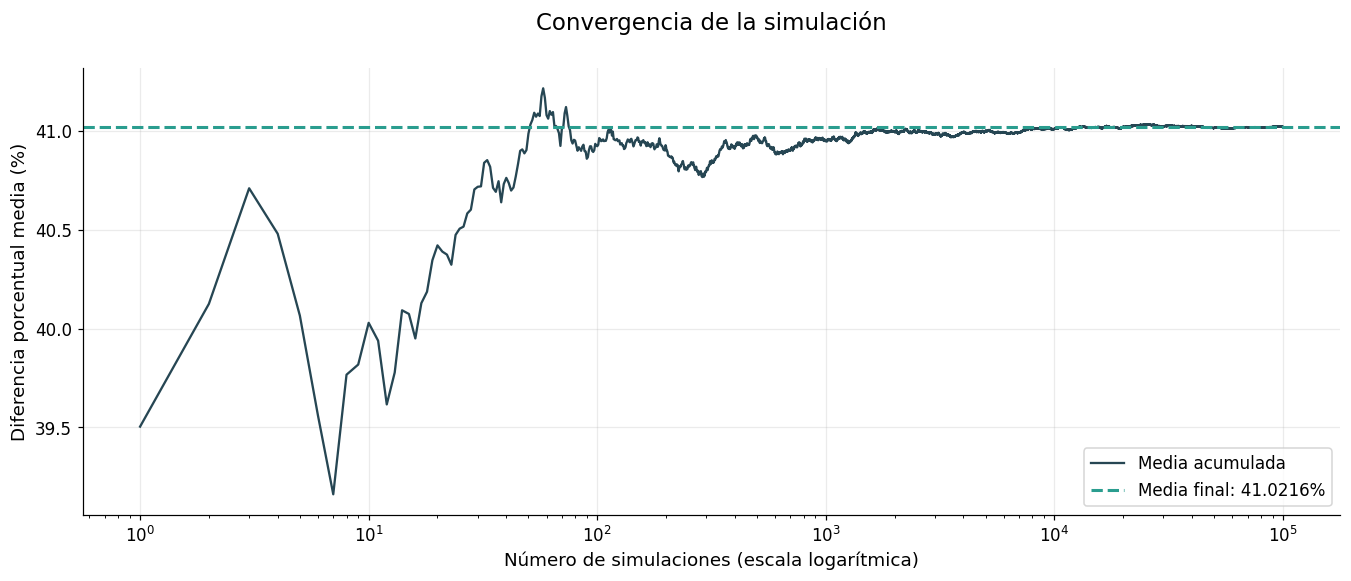

---

---
## 10. Evaluación de la hipótesis comercial


Se plantea una prueba unilateral para determinar si
la diferencia porcentual entre los precios promedio
de ambos grupos comerciales supera el 60%.

**Hipótesis nula:**

$$H_0:D\leq60\%$$

**Hipótesis alternativa:**

$$H_1:D>60\%$$

Se rechazará la hipótesis nula cuando el límite inferior
unilateral Bootstrap del 95% sea superior al 60%.


Nivel de significancia:       0.05
Umbral de comparación:        60%
Media simulada:               41.0216%
Límite inferior unilateral:   37.5094%

DECISIÓN ESTADÍSTICA
------------------------------------------------------------


**No se rechaza H0. No existe evidencia suficiente de que la diferencia comercial supere el 60%.**


El porcentaje de simulaciones que superó el umbral
establecido fue de **0.0000%**.

Esta proporción describe los resultados Bootstrap;
no representa un p-valor ni la probabilidad de que
la hipótesis sea verdadera.


... (7 outputs left out)

---
## 13. Resultados por especialidad médica

,Especialidad,Cantidad_propia,Cantidad_externa,Precio_medio_propia,Precio_medio_externa,Diferencia_media,Desviacion_estandar,Limite_inferior,Limite_superior,Limite_unilateral,Porcentaje_superior_60,Decision
0,Endocrinología,127,272,$544.22,"$1,291.24",57.68%,3.8234,49.78%,64.73%,51.16%,28.11%,No rechazar H0
1,Infectología,136,284,$314.65,$563.65,44.15%,3.9928,36.13%,51.76%,37.45%,0.00%,No rechazar H0
2,Hematología,55,94,$752.01,"$1,308.55",41.66%,8.9585,22.41%,57.41%,25.94%,0.93%,No rechazar H0
3,Ginecología,52,176,$468.83,$767.94,38.77%,6.6559,25.01%,51.07%,27.40%,0.01%,No rechazar H0
4,Cardiología,158,433,$701.16,"$1,141.61",38.52%,4.4724,29.34%,46.90%,30.92%,0.00%,No rechazar H0
5,Dermatología,33,215,$453.81,$687.16,33.81%,9.7088,14.01%,52.04%,17.40%,0.16%,No rechazar H0
6,Alergología,30,92,$334.04,$501.02,33.19%,8.1481,16.10%,48.11%,19.21%,0.01%,No rechazar H0
7,Gastroenterología,146,459,$487.09,$599.69,18.66%,10.9199,-5.06%,37.65%,-0.49%,0.00%,No rechazar H0


---
## 14. Comparación gráfica por especialidad


    Las barras representan las diferencias porcentuales
    promedio obtenidas mediante Monte Carlo.

    Los segmentos negros representan los intervalos
    Bootstrap del 95% y la línea roja indica el umbral
    del 60%.

    Los valores negativos indican que el precio promedio
    de marca propia es superior al de marca externa.
    

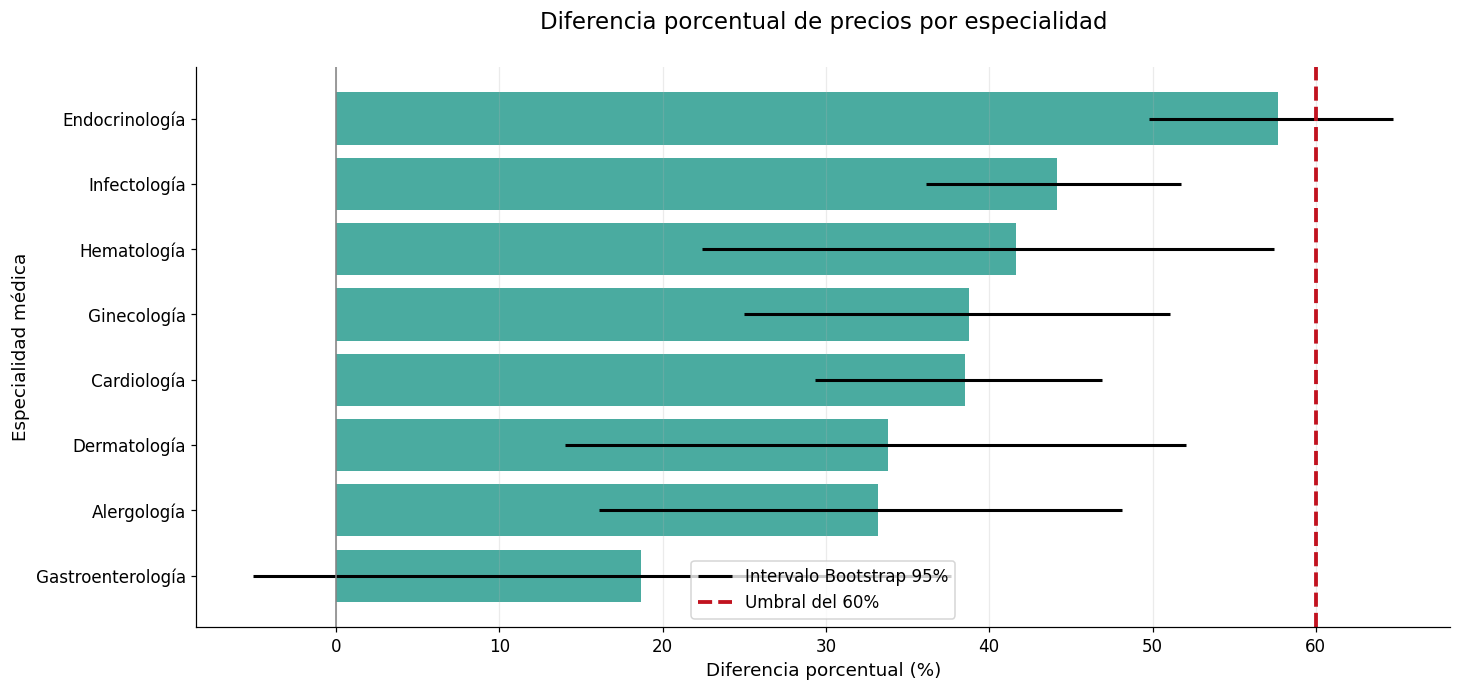

---

---
## 15. Distribución de precios por tipo de marca


El diagrama de caja permite comparar las medianas,
la dispersión y los valores atípicos de ambos grupos.

Se utiliza una escala logarítmica debido a que los precios
pueden presentar diferencias considerables de magnitud.

Los valores atípicos no se eliminan de la simulación.


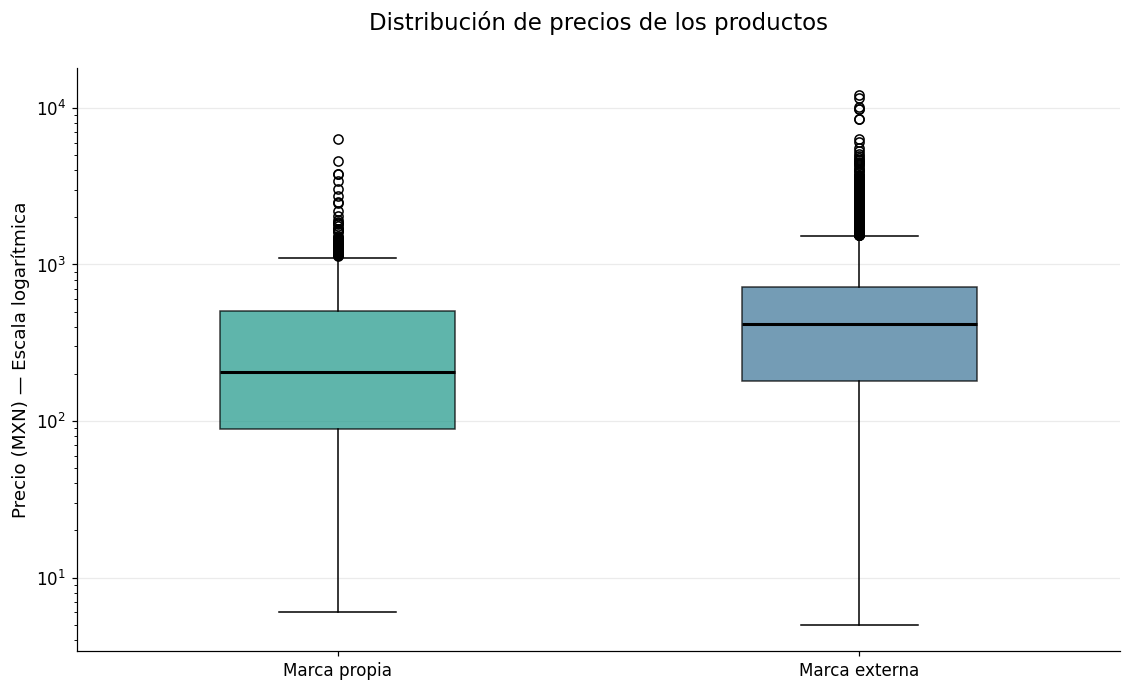

---

---
## 16. Conclusiones generales del análisis


### Resultados principales

- Registros analizados: **5,499**
- Simulaciones generales realizadas: **100,000**
- Precio promedio marca propia: **$348.13 MXN**
- Precio promedio marca externa: **$590.53 MXN**
- Diferencia porcentual observada: **41.0471%**
- Diferencia media simulada: **41.0216%**
- Desviación estándar: **2.0998**
- Error de Monte Carlo: **0.006640**
- Intervalo Bootstrap del 95%:
  **[36.8070%, 45.0290%]**

### Interpretación económica

Los productos de marca propia presentan un precio promedio 41.05% inferior al de los productos de marca externa.

### Interpretación estadística

No se rechaza H0. No existe evidencia suficiente de que la diferencia comercial supere el 60%.

El método de Monte Carlo permitió estimar la distribución
de las diferencias de precios y cuantificar la incertidumbre
asociada al procedimiento de remuestreo.



### Interpretación por especialidad

- Especialidades analizadas:
  **8**

- Especialidad con mayor diferencia simulada:
  **Endocrinología**
  (57.68%).

- Especialidad con menor diferencia simulada:
  **Gastroenterología**
  (18.66%).

- Especialidades cuyo límite inferior unilateral
  supera el 60%: **0**.

Los resultados muestran las diferencias comerciales
observadas entre especialidades. No constituyen una
prueba formal de diferencias entre todas las especialidades.



### Limitaciones del estudio

La base corresponde a una sola fecha de extracción.

La clasificación comercial no garantiza que los productos
sean medicamentos genéricos o de patente.

Las diferencias pueden estar relacionadas con la composición
de los grupos, concentraciones, presentaciones y tipos
de productos.

Los intervalos Bootstrap suponen que los registros son
representativos y pueden remuestrearse dentro de cada grupo.

Los contrastes por especialidad son exploratorios y no
incluyen ajustes por comparaciones múltiples.

Por lo tanto, las conclusiones se limitan al análisis
comercial de los productos incluidos en la base de datos.

---

### Simulación de Monte Carlo finalizada


In [ ]:
# ============================================================
# PROYECTO DE WEB SCRAPING - FARMACIAS DEL AHORRO
# ANALISIS: SIMULACION DE MONTE CARLO
# METODO: BOOTSTRAP NO PARAMETRICO
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from IPython.display import display, Markdown

# Configuracion general de las graficas

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Funcion para separar visualmente los resultados

def titulo(texto):
    display(Markdown("---\n## " + texto))

def explicar(texto):
    display(Markdown(texto))

def mostrar_grafica():
    plt.tight_layout(pad=3)
    plt.show()
    plt.close()
    display(Markdown("---"))

# ============================================================
# 1. INTRODUCCION DEL PROYECTO
# ============================================================

display(Markdown("""
# Simulación de Monte Carlo
### Farmacias del Ahorro — Análisis de precios

**Objetivo general**

Analizar las diferencias económicas entre los productos
de marca propia y marcas externas de Farmacias del Ahorro,
utilizando información obtenida mediante Web Scraping.

**Objetivo de la simulación**

Estimar la distribución de la diferencia porcentual de
precios promedio mediante remuestreo aleatorio con reemplazo.

**Hipótesis original del proyecto**

La diferencia media de precios entre medicamentos de
patente y genéricos supera el 60%, con variaciones
según la clase terapéutica.

**Alcance del análisis**

La base de datos no permite identificar de manera confiable
los medicamentos genéricos y de patente. Por ello, se realiza
una comparación comercial entre marcas propias y externas.

Los resultados no constituyen una comparación directa de
medicamentos farmacológicamente equivalentes.
"""))

# ============================================================
# 2. LECTURA DE LA BASE DE DATOS
# ============================================================

titulo("1. Lectura de la base de datos")

archivo = "DataLimpia.xlsx"

df = pd.read_excel(archivo, sheet_name="Productos")

explicar("""
Se importa la base limpia obtenida del proceso de Web Scraping.
Se conserva la información original y únicamente se seleccionan
los registros válidos para realizar la simulación.
""")

print(f"Registros originales: {len(df):,}")
print(f"Columnas originales:  {len(df.columns):,}")

print("\nPrimeros cinco registros de las variables de estudio:")

display(df[[
    "Nombre_producto",
    "Marca",
    "Precio_actual",
    "Es_marca_propia"
]].head())

# ============================================================
# 3. PARAMETROS DE LA SIMULACION
# ============================================================

titulo("2. Parámetros de la simulación")

num_simulaciones = 100000
semilla = 42
nivel_confianza = 0.95
alfa = 1 - nivel_confianza
umbral = 60
minimo_productos = 10

# Generador de numeros pseudoaleatorios

generador = np.random.default_rng(semilla)

explicar("""
Se realizan 100,000 simulaciones para aproximar
la distribución de las diferencias de precios.

La semilla permite reproducir los resultados,
mientras que el nivel de confianza del 95%
permite cuantificar la incertidumbre estadística.
""")

print(f"Número de simulaciones:    {num_simulaciones:,}")
print(f"Semilla aleatoria:         {semilla}")
print(f"Nivel de confianza:        {nivel_confianza:.0%}")
print(f"Nivel de significancia:    {alfa:.0%}")
print(f"Umbral de comparación:     {umbral}%")
print(f"Mínimo por grupo médico:   {minimo_productos}")

# ============================================================
# 4. PREPARACION DE LOS DATOS
# ============================================================

titulo("3. Preparación de las variables")

# Convertir las variables de estudio a formato numerico

df["Precio_actual"] = pd.to_numeric(
    df["Precio_actual"], errors="coerce"
)

df["Es_marca_propia"] = pd.to_numeric(
    df["Es_marca_propia"], errors="coerce"
)

# Clasificar los productos segun el indicador del Excel

df["Tipo_marca"] = df["Es_marca_propia"].map({
    1: "Marca propia",
    0: "Marca externa"
})

# Seleccionar precios positivos, finitos y marcas clasificadas

datos = df[
    (df["Precio_actual"] > 0) &
    np.isfinite(df["Precio_actual"]) &
    (df["Es_marca_propia"].isin([0, 1]))
].copy()

# Extraer los precios de cada grupo

precios_propia = datos.loc[
    datos["Es_marca_propia"] == 1,
    "Precio_actual"
].to_numpy()

precios_externa = datos.loc[
    datos["Es_marca_propia"] == 0,
    "Precio_actual"
].to_numpy()

cantidad_propia = len(precios_propia)
cantidad_externa = len(precios_externa)

if min(cantidad_propia, cantidad_externa) < 2:
    raise ValueError("No existen suficientes datos para simular.")

excluidos = len(df) - len(datos)

porcentaje_excluido = excluidos / len(df) * 100

explicar("""
Se forman dos grupos de estudio utilizando la variable
Es_marca_propia:

- Valor 1: productos de marca propia.
- Valor 0: productos de marcas externas.

Los registros sin precio válido o sin clasificación
se excluyen únicamente de la simulación.
""")

print(f"Productos de marca propia:    {cantidad_propia:,}")
print(f"Productos de marca externa:   {cantidad_externa:,}")
print(f"Total de registros utilizados: {len(datos):,}")
print(f"Registros excluidos:           {excluidos:,}")
print(f"Porcentaje excluido:           {porcentaje_excluido:.4f}%")

if porcentaje_excluido <= 10:
    print("\nSe cumple el límite del 10% de registros excluidos.")
else:
    print("\nAdvertencia: se supera el límite del 10%.")

# ============================================================
# 5. ANALISIS ESTADISTICO DESCRIPTIVO
# ============================================================

titulo("4. Estadística descriptiva")

explicar("""
Antes de realizar la simulación se calculan las principales
medidas de tendencia central y dispersión.

Esto permite conocer el comportamiento inicial de los
precios y las diferencias entre los grupos comerciales.
""")

estadisticas = datos.groupby("Tipo_marca")["Precio_actual"].agg(
    Cantidad="count",
    Media="mean",
    Mediana="median",
    Varianza="var",
    Desviacion_estandar="std",
    Minimo="min",
    Maximo="max"
).T

display(estadisticas.style.format("{:,.2f}"))

media_propia = np.mean(precios_propia)
media_externa = np.mean(precios_externa)

# Diferencia porcentual respecto al precio de marca externa

diferencia_observada = (
    1 - media_propia / media_externa
) * 100

print("\nRESULTADOS OBSERVADOS")
print("-" * 55)

print(f"Precio promedio marca propia:   ${media_propia:,.2f}")
print(f"Precio promedio marca externa:  ${media_externa:,.2f}")
print(f"Diferencia porcentual:           {diferencia_observada:.4f}%")

# ============================================================
# 6. GRAFICA DE PRECIOS PROMEDIO
# ============================================================

titulo("5. Comparación de precios promedio")

explicar("""
La siguiente gráfica compara los precios promedio observados
en la base de datos antes de realizar las simulaciones.

Permite identificar cuál de los dos grupos presenta
un precio promedio mayor.
""")

plt.figure(figsize=(10, 6))

barras = plt.bar(
    ["Marca propia", "Marca externa"],
    [media_propia, media_externa],
    color=["#2A9D8F", "#264653"],
    width=0.45
)

for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + max(media_propia, media_externa) * 0.02,
        f"${altura:,.2f}",
        ha="center",
        fontsize=13,
        fontweight="bold"
    )

plt.title("Precios promedio por tipo de marca", pad=25)
plt.ylabel("Precio promedio (MXN)")
plt.ylim(0, max(media_propia, media_externa) * 1.20)
plt.grid(axis="y", alpha=0.25)

mostrar_grafica()

# ============================================================
# 7. METODO DE MONTE CARLO
# ============================================================

titulo("6. Simulación de Monte Carlo")

explicar(r"""
Se utiliza el método Bootstrap no paramétrico porque
permite generar muestras aleatorias a partir de los
precios reales, sin asumir una distribución específica.

En cada iteración:

1. Se seleccionan precios de marca propia con reemplazo.
2. Se seleccionan precios de marca externa con reemplazo.
3. Se calcula el precio promedio de cada muestra.
4. Se obtiene la diferencia porcentual.
5. Se almacena el resultado de la simulación.

La diferencia porcentual se calcula mediante:

$$
D_i=
\left(
1-\frac{\overline{P}_{propia,i}}
{\overline{P}_{externa,i}}
\right)100
$$

El procedimiento se repite 100,000 veces.
""")

def monte_carlo(propia, externa, simulaciones):

    # Aerreglo para almacenar las diferencias simuladas

    diferencias = np.zeros(simulaciones)

    # Tamaño de las muestras originales

    n_propia = len(propia)
    n_externa = len(externa)

    for i in range(simulaciones):

        # Remuestreo aleatorio con reemplazo

        muestra_propia = generador.choice(
            propia,
            size=n_propia,
            replace=True
        )

        muestra_externa = generador.choice(
            externa,
            size=n_externa,
            replace=True
        )

        # Calcular los precios promedio simulados

        promedio_propia = np.mean(muestra_propia)

        promedio_externa = np.mean(muestra_externa)

        # Calcular y almacenar la diferencia porcentual

        diferencias[i] = (
            1 - promedio_propia / promedio_externa
        ) * 100

    return diferencias


print("Iniciando simulación general...\n")

resultados = monte_carlo(
    precios_propia,
    precios_externa,
    num_simulaciones
)

print("Simulación general completada correctamente.")
print(f"Total de iteraciones realizadas: {len(resultados):,}")

# Mostrar una parte de las simulaciones realizadas

primeras_simulaciones = pd.DataFrame({
    "Iteracion": np.arange(1, 11),
    "Diferencia_porcentual": resultados[:10]
})

print("\nPrimeras diez iteraciones:")

display(primeras_simulaciones.style.format({
    "Diferencia_porcentual": "{:.4f}%"
}))

# ============================================================
# 8. RESULTADOS ESTADISTICOS DE MONTE CARLO
# ============================================================

titulo("7. Resultados estadísticos de Monte Carlo")

# Medidas de tendencia central

media_simulada = np.mean(resultados)
mediana_simulada = np.median(resultados)

# Medidas de dispersion

varianza = np.var(resultados, ddof=1)
desviacion = np.std(resultados, ddof=1)

# Error numerico de la media simulada

error_monte_carlo = desviacion / np.sqrt(num_simulaciones)

# Intervalo de confianza Bootstrap bilateral

limite_inferior, limite_superior = np.quantile(
    resultados,
    [alfa / 2, 1 - alfa / 2]
)

# Limite inferior unilateral al 95%

limite_unilateral = np.quantile(resultados, alfa)

# Frecuencia relativa de simulaciones superiores al umbral

proporcion_superior = np.mean(
    resultados > umbral
) * 100

explicar(r"""
La media simulada representa la diferencia porcentual
promedio obtenida en las 100,000 iteraciones.

$$
\widehat{\mu}_{MC}=
\frac{1}{N}\sum_{i=1}^{N}D_i
$$

La varianza y la desviación estándar permiten analizar
la dispersión de las diferencias simuladas.

El error estándar de Monte Carlo mide la precisión
numérica de la media obtenida:

$$
EE_{MC}=\frac{S}{\sqrt{N}}
$$

El intervalo Bootstrap se obtiene mediante los
percentiles de la distribución simulada.
""")

tabla_resultados = pd.DataFrame({

    "Indicador": [
        "Diferencia observada",
        "Media simulada",
        "Mediana simulada",
        "Varianza",
        "Desviación estándar",
        "Error de Monte Carlo",
        "Valor mínimo",
        "Valor máximo",
        "Límite inferior IC 95%",
        "Límite superior IC 95%",
        "Límite unilateral 95%",
        "Simulaciones superiores al 60%"
    ],

    "Resultado": [
        f"{diferencia_observada:.4f}%",
        f"{media_simulada:.4f}%",
        f"{mediana_simulada:.4f}%",
        f"{varianza:.4f}",
        f"{desviacion:.4f}",
        f"{error_monte_carlo:.6f}",
        f"{np.min(resultados):.4f}%",
        f"{np.max(resultados):.4f}%",
        f"{limite_inferior:.4f}%",
        f"{limite_superior:.4f}%",
        f"{limite_unilateral:.4f}%",
        f"{proporcion_superior:.4f}%"
    ]
})

display(tabla_resultados)

# ============================================================
# 9. DISTRIBUCION DE MONTE CARLO
# ============================================================

titulo("8. Distribución de las diferencias simuladas")

explicar("""
El histograma representa la distribución empírica de las
100,000 diferencias porcentuales obtenidas.

La línea negra representa la media simulada, la región verde
corresponde al intervalo Bootstrap del 95% y la línea roja
indica el umbral del 60% establecido para la comparación.
""")

plt.figure(figsize=(13, 7))

plt.hist(
    resultados,
    bins=60,
    density=True,
    color="#457B9D",
    edgecolor="white",
    alpha=0.85,
    label="Distribución Bootstrap"
)

plt.axvline(
    media_simulada,
    color="black",
    linestyle="--",
    linewidth=2.5,
    label=f"Media simulada: {media_simulada:.2f}%"
)

plt.axvspan(
    limite_inferior,
    limite_superior,
    color="#2A9D8F",
    alpha=0.20,
    label="Intervalo de confianza 95%"
)

plt.axvline(
    umbral,
    color="#C1121F",
    linestyle="--",
    linewidth=2.5,
    label=f"Umbral: {umbral}%"
)

plt.title(
    "Distribución de diferencias porcentuales de precios",
    pad=25
)

plt.xlabel("Diferencia porcentual de precios (%)")
plt.ylabel("Densidad de probabilidad")
plt.legend(loc="upper right")
plt.grid(alpha=0.20)

mostrar_grafica()

# ============================================================
# 10. ANALISIS DE CONVERGENCIA
# ============================================================

titulo("9. Convergencia del método de Monte Carlo")

explicar("""
La gráfica de convergencia muestra cómo cambia la media
acumulada conforme aumenta el número de simulaciones.

Una estabilización de la media indica que el estimador
numérico presenta menor variabilidad conforme se realizan
más iteraciones.
""")

iteraciones = np.arange(1, num_simulaciones + 1)

media_acumulada = np.cumsum(resultados) / iteraciones

# Mostrar la convergencia en diferentes iteraciones

puntos_control = np.array([
    10, 100, 1000, 10000, 50000, 100000
])

puntos_control = puntos_control[
    puntos_control <= num_simulaciones
]

tabla_convergencia = pd.DataFrame({
    "Iteraciones": puntos_control,
    "Media_acumulada": media_acumulada[puntos_control - 1],
    "Error_Monte_Carlo": [
        np.std(resultados[:n], ddof=1) / np.sqrt(n)
        for n in puntos_control
    ]
})

display(tabla_convergencia.style.format({
    "Iteraciones": "{:,}",
    "Media_acumulada": "{:.4f}%",
    "Error_Monte_Carlo": "{:.6f}"
}))

plt.figure(figsize=(13, 6))

plt.plot(
    iteraciones,
    media_acumulada,
    color="#264653",
    linewidth=1.5,
    label="Media acumulada"
)

plt.axhline(
    media_simulada,
    color="#2A9D8F",
    linestyle="--",
    linewidth=2,
    label=f"Media final: {media_simulada:.4f}%"
)

plt.xscale("log")

plt.title("Convergencia de la simulación", pad=25)
plt.xlabel("Número de simulaciones (escala logarítmica)")
plt.ylabel("Diferencia porcentual media (%)")
plt.legend()
plt.grid(alpha=0.25)

mostrar_grafica()

# ============================================================
# 11. EVALUACION DE LA HIPOTESIS
# ============================================================

titulo("10. Evaluación de la hipótesis comercial")

explicar(r"""
Se plantea una prueba unilateral para determinar si
la diferencia porcentual entre los precios promedio
de ambos grupos comerciales supera el 60%.

**Hipótesis nula:**

$$H_0:D\leq60\%$$

**Hipótesis alternativa:**

$$H_1:D>60\%$$

Se rechazará la hipótesis nula cuando el límite inferior
unilateral Bootstrap del 95% sea superior al 60%.
""")

print(f"Nivel de significancia:       {alfa:.2f}")
print(f"Umbral de comparación:        {umbral}%")
print(f"Media simulada:               {media_simulada:.4f}%")
print(f"Límite inferior unilateral:   {limite_unilateral:.4f}%")

print("\nDECISIÓN ESTADÍSTICA")
print("-" * 60)

if limite_unilateral > umbral:

    conclusion = (
        "Se rechaza H0. Existe evidencia estadística "
        "de que la diferencia comercial supera el 60%."
    )

else:

    conclusion = (
        "No se rechaza H0. No existe evidencia suficiente "
        "de que la diferencia comercial supere el 60%."
    )

explicar(f"**{conclusion}**")

explicar(f"""
El porcentaje de simulaciones que superó el umbral
establecido fue de **{proporcion_superior:.4f}%**.

Esta proporción describe los resultados Bootstrap;
no representa un p-valor ni la probabilidad de que
la hipótesis sea verdadera.
""")

# ============================================================
# 12. EXTRACCION DE ESPECIALIDADES MEDICAS
# ============================================================

titulo("11. Identificación de especialidades médicas")

explicar("""
Se extraen las especialidades médicas de la columna
Categorias_encontradas para realizar comparaciones
entre marcas dentro de cada clasificación.

Un producto puede pertenecer a varias especialidades,
por lo que los grupos no son necesariamente independientes.
""")

def extraer_especialidades(texto):

    especialidades = re.findall(
        r"\|\s*([^|]+?)\s*-\s*Especialidades\s*-\s*Farmacia",
        str(texto),
        flags=re.IGNORECASE
    )

    especialidades = sorted(set(
        especialidad.strip()
        for especialidad in especialidades
    ))

    return especialidades or ["Sin especialidad"]

datos["Especialidad"] = datos[
    "Categorias_encontradas"
].apply(extraer_especialidades)

# Separar los productos que pertenecen a varias especialidades

datos_especialidad = datos.explode("Especialidad")

# Excluir productos que no tienen especialidad identificada

datos_especialidad = datos_especialidad[
    datos_especialidad["Especialidad"] != "Sin especialidad"
].copy()

distribucion = pd.crosstab(
    datos_especialidad["Especialidad"],
    datos_especialidad["Tipo_marca"]
)

print("Distribución de productos por especialidad:\n")

display(distribucion)

# ============================================================
# 13. SIMULACION POR ESPECIALIDAD
# ============================================================

titulo("12. Simulación de Monte Carlo por especialidad")

explicar("""
Se aplica nuevamente el método Bootstrap a cada especialidad
médica para determinar si la diferencia comercial de precios
presenta variaciones según la categoría de los productos.

Se establece un mínimo de 10 productos por tipo de marca
como criterio exploratorio de inclusión.

Las especialidades con menos registros no se eliminan
de la base original, únicamente se omiten de este análisis.
""")

resultados_especialidad = []

for especialidad, grupo in datos_especialidad.groupby(
    "Especialidad"
):

    propia = grupo.loc[
        grupo["Es_marca_propia"] == 1,
        "Precio_actual"
    ].to_numpy()

    externa = grupo.loc[
        grupo["Es_marca_propia"] == 0,
        "Precio_actual"
    ].to_numpy()

    if (
        len(propia) >= minimo_productos and
        len(externa) >= minimo_productos
    ):

        simulacion = monte_carlo(
            propia,
            externa,
            num_simulaciones
        )

        inferior, superior = np.quantile(
            simulacion,
            [alfa / 2, 1 - alfa / 2]
        )

        unilateral = np.quantile(simulacion, alfa)

        resultados_especialidad.append({

            "Especialidad": especialidad,

            "Cantidad_propia": len(propia),

            "Cantidad_externa": len(externa),

            "Precio_medio_propia": np.mean(propia),

            "Precio_medio_externa": np.mean(externa),

            "Diferencia_media": np.mean(simulacion),

            "Desviacion_estandar": np.std(
                simulacion, ddof=1
            ),

            "Limite_inferior": inferior,

            "Limite_superior": superior,

            "Limite_unilateral": unilateral,

            "Porcentaje_superior_60": np.mean(
                simulacion > umbral
            ) * 100,

            "Decision": (
                "Rechazar H0"
                if unilateral > umbral
                else "No rechazar H0"
            )

        })

        print(f"Simulación completada: {especialidad}")

    else:

        print(f"Datos insuficientes: {especialidad}")


tabla_especialidades = pd.DataFrame(
    resultados_especialidad
)

if not tabla_especialidades.empty:

    tabla_especialidades = (
        tabla_especialidades
        .sort_values("Diferencia_media", ascending=False)
        .reset_index(drop=True)
    )

    titulo("13. Resultados por especialidad médica")

    display(tabla_especialidades.style.format({
        "Precio_medio_propia": "${:,.2f}",
        "Precio_medio_externa": "${:,.2f}",
        "Diferencia_media": "{:.2f}%",
        "Desviacion_estandar": "{:.4f}",
        "Limite_inferior": "{:.2f}%",
        "Limite_superior": "{:.2f}%",
        "Limite_unilateral": "{:.2f}%",
        "Porcentaje_superior_60": "{:.2f}%"
    }))

else:

    print("\nNo existen especialidades con suficientes registros.")

# ============================================================
# 14. GRAFICA DE DIFERENCIAS POR ESPECIALIDAD
# ============================================================

if not tabla_especialidades.empty:

    titulo("14. Comparación gráfica por especialidad")

    explicar("""
    Las barras representan las diferencias porcentuales
    promedio obtenidas mediante Monte Carlo.

    Los segmentos negros representan los intervalos
    Bootstrap del 95% y la línea roja indica el umbral
    del 60%.

    Los valores negativos indican que el precio promedio
    de marca propia es superior al de marca externa.
    """)

    tabla_grafica = tabla_especialidades.sort_values(
        "Diferencia_media"
    )

    colores = [
        "#2A9D8F" if valor >= 0 else "#E76F51"
        for valor in tabla_grafica["Diferencia_media"]
    ]

    plt.figure(figsize=(
        14,
        max(7, len(tabla_grafica) * 0.65)
    ))

    posiciones = np.arange(len(tabla_grafica))

    plt.barh(
        posiciones,
        tabla_grafica["Diferencia_media"],
        color=colores,
        alpha=0.85
    )

    # Incorporar intervalos de confianza

    plt.hlines(
        posiciones,
        tabla_grafica["Limite_inferior"],
        tabla_grafica["Limite_superior"],
        color="black",
        linewidth=2,
        label="Intervalo Bootstrap 95%"
    )

    plt.yticks(
        posiciones,
        tabla_grafica["Especialidad"]
    )

    plt.axvline(
        umbral,
        color="#C1121F",
        linestyle="--",
        linewidth=2.5,
        label="Umbral del 60%"
    )

    plt.axvline(
        0,
        color="gray",
        linewidth=1
    )

    plt.title(
        "Diferencia porcentual de precios por especialidad",
        pad=25
    )

    plt.xlabel("Diferencia porcentual (%)")
    plt.ylabel("Especialidad médica")
    plt.legend(loc="best")
    plt.grid(axis="x", alpha=0.25)

    mostrar_grafica()

# ============================================================
# 15. DIAGRAMA DE CAJA DE LOS PRECIOS
# ============================================================

titulo("15. Distribución de precios por tipo de marca")

explicar("""
El diagrama de caja permite comparar las medianas,
la dispersión y los valores atípicos de ambos grupos.

Se utiliza una escala logarítmica debido a que los precios
pueden presentar diferencias considerables de magnitud.

Los valores atípicos no se eliminan de la simulación.
""")

plt.figure(figsize=(11, 7))

cajas = plt.boxplot(
    [precios_propia, precios_externa],
    patch_artist=True,
    widths=0.45,
    medianprops={
        "color": "black",
        "linewidth": 2
    }
)

plt.xticks(
    [1, 2],
    ["Marca propia", "Marca externa"]
)

for caja, color in zip(
    cajas["boxes"],
    ["#2A9D8F", "#457B9D"]
):
    caja.set_facecolor(color)
    caja.set_alpha(0.75)

plt.yscale("log")

plt.title("Distribución de precios de los productos", pad=25)
plt.ylabel("Precio (MXN) — Escala logarítmica")
plt.grid(axis="y", alpha=0.25)

mostrar_grafica()

# ============================================================
# 16. CONCLUSIONES GENERALES
# ============================================================

titulo("16. Conclusiones generales del análisis")

# Interpretar el signo de la diferencia observada

if diferencia_observada >= 0:

    interpretacion = (
        f"Los productos de marca propia presentan un precio "
        f"promedio {diferencia_observada:.2f}% inferior "
        f"al de los productos de marca externa."
    )

else:

    interpretacion = (
        f"Los productos de marca propia presentan un precio "
        f"promedio {abs(diferencia_observada):.2f}% superior "
        f"al de los productos de marca externa."
    )

explicar(f"""
### Resultados principales

- Registros analizados: **{len(datos):,}**
- Simulaciones generales realizadas: **{num_simulaciones:,}**
- Precio promedio marca propia: **${media_propia:,.2f} MXN**
- Precio promedio marca externa: **${media_externa:,.2f} MXN**
- Diferencia porcentual observada: **{diferencia_observada:.4f}%**
- Diferencia media simulada: **{media_simulada:.4f}%**
- Desviación estándar: **{desviacion:.4f}**
- Error de Monte Carlo: **{error_monte_carlo:.6f}**
- Intervalo Bootstrap del 95%:
  **[{limite_inferior:.4f}%, {limite_superior:.4f}%]**

### Interpretación económica

{interpretacion}

### Interpretación estadística

{conclusion}

El método de Monte Carlo permitió estimar la distribución
de las diferencias de precios y cuantificar la incertidumbre
asociada al procedimiento de remuestreo.
""")

# Interpretar los resultados por especialidad

if not tabla_especialidades.empty:

    mayor = tabla_especialidades.iloc[0]
    menor = tabla_especialidades.iloc[-1]

    cantidad_superior = (
        tabla_especialidades["Limite_unilateral"] > umbral
    ).sum()

    explicar(f"""
### Interpretación por especialidad

- Especialidades analizadas:
  **{len(tabla_especialidades)}**

- Especialidad con mayor diferencia simulada:
  **{mayor['Especialidad']}**
  ({mayor['Diferencia_media']:.2f}%).

- Especialidad con menor diferencia simulada:
  **{menor['Especialidad']}**
  ({menor['Diferencia_media']:.2f}%).

- Especialidades cuyo límite inferior unilateral
  supera el 60%: **{cantidad_superior}**.

Los resultados muestran las diferencias comerciales
observadas entre especialidades. No constituyen una
prueba formal de diferencias entre todas las especialidades.
""")

explicar("""
### Limitaciones del estudio

La base corresponde a una sola fecha de extracción.

La clasificación comercial no garantiza que los productos
sean medicamentos genéricos o de patente.

Las diferencias pueden estar relacionadas con la composición
de los grupos, concentraciones, presentaciones y tipos
de productos.

Los intervalos Bootstrap suponen que los registros son
representativos y pueden remuestrearse dentro de cada grupo.

Los contrastes por especialidad son exploratorios y no
incluyen ajustes por comparaciones múltiples.

Por lo tanto, las conclusiones se limitan al análisis
comercial de los productos incluidos en la base de datos.

---

### Simulación de Monte Carlo finalizada
""")